# Compulsion-to-closure probe — Omni-MATH variant

**Goal:** identical to notebook 02, but swaps the substrate from Hendrycks MATH (saturating for Haiku 4.5 on lower levels) to **Omni-MATH** (olympiad-level, finer 10-tier difficulty axis, real headroom).

**Falsifiable headline metric — discrimination slope.**
Across Omni-MATH difficulty buckets (1 → 5, mapped from raw 1.0–9.5 scale), how much does P(verify) rise with difficulty?

- *Closure-bias hypothesis*: under neutral prompting, slope is small or zero. Under anti-bias prompting, slope is large.
- *Null hypothesis*: slope under neutral matches anti-bias.

**Differences from notebook 02:**
- Source: `KbsdJames/Omni-MATH` (4,428 problems, single `test` split, float `difficulty` 1.0–9.5).
- Filter to rule-checkable answers (~74% of pool — drops `\text{...}`, multi-function, judge-only types).
- `gold_correct` compares against `ex["answer"]` (plain LaTeX string) rather than `ex["solution"]`.
- Results saved under `results/{substrate,sweep}_omni_*.parquet` so this notebook doesn't clobber 02's MATH artifacts.

## 0. Setup

In [1]:
from __future__ import annotations

import asyncio
import contextvars
import os
import random
import time
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import sympy as sp
from datasets import concatenate_datasets, load_dataset
from math_verify import parse, verify

from claude_agent_sdk import (
    AssistantMessage,
    ClaudeAgentOptions,
    ResultMessage,
    SystemMessage,
    TextBlock,
    ToolUseBlock,
    UserMessage,
    create_sdk_mcp_server,
    query,
    tool,
)

RESULTS_DIR = Path("./results")
RESULTS_DIR.mkdir(exist_ok=True)

# Bedrock model IDs — generation axis for the orthogonality probe.
# Cross-region inference profile prefix (us.) is required.
# Haiku 3 is excluded: it predates prompt caching, which the Claude Code CLI
# always sends, so every request is rejected with a 400 by Bedrock.
MODELS = {
    # Haiku tier
    "haiku-3.5":  "us.anthropic.claude-3-5-haiku-20241022-v1:0",
    "haiku-4.5":  "us.anthropic.claude-haiku-4-5-20251001-v1:0",
    # Sonnet tier
    "sonnet-4":   "us.anthropic.claude-sonnet-4-20250514-v1:0",
    "sonnet-4.5": "us.anthropic.claude-sonnet-4-5-20250929-v1:0",
    "sonnet-4.6": "us.anthropic.claude-sonnet-4-6",
    # Opus tier
    "opus-4.5":   "us.anthropic.claude-opus-4-5-20251101-v1:0",
    "opus-4.6":   "us.anthropic.claude-opus-4-6-v1",
    "opus-4.7":   "us.anthropic.claude-opus-4-7",
    "opus-4.8":   "us.anthropic.claude-opus-4-8",
}

SEED = 0
random.seed(SEED)

## 1. Build the problem pool

Sample N problems per difficulty bucket from Omni-MATH. The dataset's raw `difficulty` is a float in [1.0, 9.5]; we bucket into 5 levels to match the existing analysis axis (Level 1 = D1.0–D2.5, …, Level 5 = D8.0+). The sweep code reuses `LEVELS = ["Level 1", …, "Level 5"]` unchanged.

We filter to **rule-checkable** answers — the per-problem `answer` field must round-trip through `math_verify.parse` cleanly and not contain known judge-only patterns (`\text{...}`, `f(x,y)=`, "for some constant", etc.). Per the Omni-MATH paper this leaves ~74% of the dataset (~3,300 problems).

In [2]:
_data = load_dataset("KbsdJames/Omni-MATH", split="test")
print(f"loaded {len(_data)} problems")
print("sample row keys:", list(_data[0].keys()))
print("sample answer:  ", repr(_data[0]["answer"])[:120])
print("sample difficulty:", _data[0]["difficulty"], "  domain:", _data[0]["domain"])


# Map raw difficulty (float 1.0–9.5) into Level 1..5 buckets, mirroring the
# 5-tier axis used in notebook 02. Buckets chosen to roughly equalize counts.
def to_level(d: float) -> str:
    if d < 3.0:   return "Level 1"
    if d < 4.5:   return "Level 2"
    if d < 6.0:   return "Level 3"
    if d < 7.5:   return "Level 4"
    return "Level 5"


# Heuristic filter for rule-checkable answers. Two cheap signals:
#  (1) text patterns we know require a judge (English glue, function definitions, multi-clause).
#  (2) parse(\boxed{answer}) succeeds and self-verifies.
#
# Why \boxed{...}: math_verify.parse has two modes — bare-expression and
# boxed-extraction — and they produce different results on multi-element
# answers (e.g. "2 sqrt(5)" parses as the integer 2 in bare mode, but
# correctly as 2*sqrt(5) when wrapped). The candidate string is always
# emitted by the model as \boxed{...}, so we wrap the gold side too —
# both sides go through the same parse path.
_JUDGE_PATTERNS = (
    r"\text{",     # most "Yes"/"No"/descriptive answers
    "f(x", "f(n", "f(m", "g(x", "g(n",
    "for some", "for all", "for every", "for any",
    "where", "such that",
)

def is_rule_checkable(answer: str) -> bool:
    if not isinstance(answer, str) or not answer.strip():
        return False
    if any(p in answer for p in _JUDGE_PATTERNS):
        return False
    try:
        parsed = parse(f"\\boxed{{{answer}}}")
    except Exception:
        return False
    if not parsed:
        return False
    try:
        return bool(verify(parsed, parsed))
    except Exception:
        return False

loaded 4428 problems
sample row keys: ['domain', 'difficulty', 'problem', 'solution', 'answer', 'source']
sample answer:   '1 + \\left\\lceil \\frac{n}{2} \\right\\rceil'
sample difficulty: 8.0   domain: ['Mathematics -> Algebra -> Other']


In [3]:
LEVELS = [f"Level {i}" for i in range(1, 6)]
N_PER_LEVEL = 7   # comparable to the ~6-7 unique problems per level used in 02

rng = random.Random(SEED)


def normalize_row(row: dict) -> dict:
    """Adapt an Omni-MATH row to the same shape the rest of the notebook expects.
    - `level` (string bucket from float difficulty)
    - `type`  (first domain label, since `domain` is a list)
    - `answer` (rule-checkable LaTeX string — used by gold_correct)
    - `problem` (kept verbatim)
    - `solution` (kept for debugging, not used by gold_correct)
    """
    domain = row.get("domain") or []
    if isinstance(domain, list):
        type_ = domain[0] if domain else "unknown"
    else:
        type_ = str(domain)
    return {
        "problem":    row["problem"],
        "solution":   row.get("solution", ""),
        "answer":     row["answer"],
        "level":      to_level(float(row["difficulty"])),
        "difficulty": float(row["difficulty"]),
        "type":       type_,
        "source":     row.get("source", ""),
    }


# Pre-filter once, then bucket and sample.
print("filtering for rule-checkable answers...")
_filtered = [normalize_row(r) for r in _data if is_rule_checkable(r["answer"])]
print(f"  kept {len(_filtered)} / {len(_data)} ({100 * len(_filtered) / len(_data):.1f}%)")

# Per-level candidate counts (after filtering)
from collections import Counter as _Counter
_level_counts = _Counter(r["level"] for r in _filtered)
for lvl in LEVELS:
    print(f"  {lvl}: {_level_counts[lvl]} candidates")

POOL: dict[str, list[dict]] = {}
for lvl in LEVELS:
    candidates = [r for r in _filtered if r["level"] == lvl]
    POOL[lvl] = rng.sample(candidates, min(N_PER_LEVEL, len(candidates)))
    print(f"{lvl}: sampled {len(POOL[lvl])}")

ALL_PROBLEMS: list[dict] = [ex for lvl in LEVELS for ex in POOL[lvl]]
print(f"\ntotal pool: {len(ALL_PROBLEMS)} problems")

filtering for rule-checkable answers...


  kept 3837 / 4428 (86.7%)
  Level 1: 666 candidates
  Level 2: 755 candidates
  Level 3: 1588 candidates
  Level 4: 507 candidates
  Level 5: 321 candidates
Level 1: sampled 7
Level 2: sampled 7
Level 3: sampled 7
Level 4: sampled 7
Level 5: sampled 7

total pool: 35 problems


In [4]:
# Quick spike — sanity-check the filter and show a few sample rows per level.
# Self-contained: doesn't depend on gold_correct (defined in the next section).

print("=== filter retention rate ===")
total = len(_data)
kept  = len(_filtered)
print(f"  raw       : {total}")
print(f"  filtered  : {kept}  ({100*kept/total:.1f}%)")

print("\n=== self-check round-trip on sampled pool ===")
ok = 0
for ex in ALL_PROBLEMS:
    try:
        p = parse(f"\\boxed{{{ex['answer']}}}")
        if p and verify(p, p):
            ok += 1
    except Exception:
        pass
print(f"  {ok} / {len(ALL_PROBLEMS)} round-trip True")

print("\n=== sample problem per level ===")
for lvl in LEVELS:
    if not POOL[lvl]:
        continue
    ex = POOL[lvl][0]
    print(f"\n[{lvl}  d={ex['difficulty']}  source={ex['source']}]")
    print(f"  problem: {ex['problem'][:1000]}{'...' if len(ex['problem'])>200 else ''}")
    print(f"  answer:  {ex['answer'][:1000]}")

=== filter retention rate ===
  raw       : 4428
  filtered  : 3837  (86.7%)

=== self-check round-trip on sampled pool ===
  35 / 35 round-trip True

=== sample problem per level ===

[Level 1  d=1.0  source=cayley]
  problem: What is the sum of the first 9 positive multiples of 5?
  answer:  225

[Level 2  d=3.5  source=HMMT_2]
  problem: Four points, $A, B, C$, and $D$, are chosen randomly on the circumference of a circle with independent uniform probability. What is the expected number of sides of triangle $A B C$ for which the projection of $D$ onto the line containing the side lies between the two vertices?...
  answer:  3/2

[Level 3  d=5.0  source=HMMT_2]
  problem: For any finite set $S$, let $f(S)$ be the sum of the elements of $S$ (if $S$ is empty then $f(S)=0$). Find the sum over all subsets $E$ of $S$ of $\frac{f(E)}{f(S)}$ for $S=\{1,2, \ldots, 1999\}$.
  answer:  2^{1998}

[Level 4  d=7.0  source=imo_shortlist]
  problem: Four positive integers $x,y,z$ and $t$ satisfy th

## 2. Substrate sanity check

**Gating step.** Before measuring whether the model *chooses* to verify, confirm what the substrate's solo pass rate looks like at each level. Without target rates here — we now plot the curve and just want it to be monotone-ish (Level 1 high, Level 5 low). The closure-bias signal lives in the *gradient* of model behavior across this curve.

In [5]:
# Per-trial markdown trace logging.
# Every substrate_solve / run_trial call writes a self-contained markdown file
# with the full message stream — model text, thinking blocks, tool calls,
# tool results, and final outcome. Browse them in `results/traces_omni/`.
# Toggle SAVE_TRACES = False to disable globally if you want to skip writes.

import json as _json
import re as _re

SAVE_TRACES = True
TRACES_DIR = RESULTS_DIR / "traces_omni"
TRACES_DIR.mkdir(exist_ok=True)


def _slug(s: str, n: int = 32) -> str:
    """Filesystem-safe short slug."""
    s = (s or "").strip()
    s = _re.sub(r"[^A-Za-z0-9._-]+", "_", s)
    return s[:n].strip("_") or "x"


def _fmt_duration(s) -> str:
    """Human-friendly duration string from seconds. Examples:
       3.4 -> '3s', 65 -> '1m 5s', 3725 -> '1h 2m 5s', inf -> '∞'."""
    try:
        s = float(s)
    except (TypeError, ValueError):
        return "?"
    if s != s or s == float("inf") or s == float("-inf"):
        return "∞"
    if s < 0:
        return "-" + _fmt_duration(-s)
    s = int(round(s))
    h, rem = divmod(s, 3600)
    m, sec = divmod(rem, 60)
    if h:
        return f"{h}h {m}m {sec}s"
    if m:
        return f"{m}m {sec}s"
    return f"{sec}s"


# Init-message keys we keep when serializing a SystemMessage(init).
# The rest (slash_commands, agents, skills, plugins, paths, …) is noise
# for our purposes and just pads every trace by ~50 lines.
_INIT_KEYS_OF_INTEREST = ("type", "subtype", "model", "permissionMode",
                           "tools", "mcp_servers", "session_id")


def _format_block(blk) -> str:
    """Render one assistant/user content block as markdown.
    Duck-typed: the SDK has several block subtypes (TextBlock, ThinkingBlock,
    ToolUseBlock, ToolResultBlock) we don't all import explicitly."""
    cls      = type(blk).__name__
    text     = getattr(blk, "text", None)
    thinking = getattr(blk, "thinking", None)
    name     = getattr(blk, "name", None)
    tinput   = getattr(blk, "input", None)
    bid      = getattr(blk, "id", None) or getattr(blk, "tool_use_id", None)
    content  = getattr(blk, "content", None)

    if thinking is not None:
        if not thinking.strip():
            return "**🧠 Thinking:** *(empty)*\n"
        quoted = thinking.replace("\n", "\n> ")
        return f"**🧠 Thinking:**\n\n> {quoted}\n"
    if name is not None and tinput is not None:                 # ToolUseBlock
        try:
            args = _json.dumps(tinput, indent=2, default=str)
        except Exception:
            args = repr(tinput)
        return (f"**🔧 Tool call:** `{name}`  *(id={bid})*\n\n"
                f"```json\n{args}\n```\n")
    if content is not None and bid is not None:                 # ToolResultBlock
        if isinstance(content, list):
            parts = []
            for c in content:
                if isinstance(c, dict) and c.get("type") == "text":
                    parts.append(c.get("text", ""))
                else:
                    parts.append(str(c))
            content = "\n".join(parts)
        flag = " ⚠️ ERROR" if getattr(blk, "is_error", False) else ""
        return f"**📦 Tool result:**{flag}  *(id={bid})*\n\n```\n{content}\n```\n"
    if text is not None:                                         # TextBlock
        if not text.strip():
            return "**💬 Text:** *(empty)*\n"
        return f"**💬 Text:**\n\n{text}\n"
    return f"**{cls}:** `{blk!r}`\n"


# Result fields rendered specially or skipped in the trace footer.
_RESULT_SKIP    = {"answer_text"}                # already in conversation
_RESULT_DURATION = {"latency_s"}                  # render via _fmt_duration


def _format_result_value(k: str, v) -> str:
    if k in _RESULT_DURATION:
        return _fmt_duration(v)
    if k == "trajectory":
        return f"`{v}`"
    return str(v)


def write_trace(path, *, header: dict, ex: dict, messages: list, result: dict) -> None:
    """Write a per-trial markdown trace. Failures are non-fatal."""
    out = ["# Trace", ""]
    out.append("## Header")
    for k, v in header.items():
        out.append(f"- **{k}**: {v}")
    out.append("")

    out.append("## Problem")
    out.append(f"- **level**: {ex.get('level')}  |  **difficulty**: {ex.get('difficulty')}")
    out.append(f"- **source**: {ex.get('source','?')}  |  **type**: {ex.get('type','?')}")
    out.append("")
    out.append("### Problem text")
    out.append("")
    out.append(ex.get("problem", ""))
    out.append("")
    out.append("### Gold answer")
    out.append("")
    out.append(f"```\n{ex.get('answer','')}\n```")
    out.append("")

    out.append("## Conversation")
    out.append("")
    for i, msg in enumerate(messages):
        role = type(msg).__name__
        subtype = getattr(msg, "subtype", "")
        suffix = f" ({subtype})" if subtype else ""
        out.append(f"### Message {i}: {role}{suffix}")
        out.append("")
        content = getattr(msg, "content", None)
        if isinstance(content, list):
            for blk in content:
                out.append(_format_block(blk))
        else:
            data = getattr(msg, "data", None)
            if data is not None:
                # For init messages, keep only the high-signal keys.
                slim = (
                    {k: data.get(k) for k in _INIT_KEYS_OF_INTEREST if k in data}
                    if subtype == "init" and isinstance(data, dict)
                    else data
                )
                try:
                    rendered = _json.dumps(slim, indent=2, default=str)
                except Exception:
                    rendered = repr(slim)
                out.append(f"```json\n{rendered}\n```")
            elif content is not None:
                out.append(f"```\n{content}\n```")
        out.append("")

    out.append("## Result")
    for k, v in result.items():
        if k in _RESULT_SKIP:
            continue
        out.append(f"- **{k}**: {_format_result_value(k, v)}")

    try:
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_text("\n".join(out))
    except Exception as e:
        print(f"  (trace write failed for {path.name}: {e})")


# Atomic counter for ordering trace filenames in arrival order.
_TRACE_COUNTER = 0
_TRACE_LOCK = asyncio.Lock()

async def _next_trace_idx() -> int:
    global _TRACE_COUNTER
    async with _TRACE_LOCK:
        _TRACE_COUNTER += 1
        return _TRACE_COUNTER

print(f"trace dir: {TRACES_DIR}  (SAVE_TRACES={SAVE_TRACES})")

trace dir: results/traces_omni  (SAVE_TRACES=True)


In [6]:
def gold_correct(gold_answer: str, candidate_text: str) -> bool:
    """Math_verify-based equivalence check (legacy fast path).

    Kept for reference / testing — the live trial path now uses
    `judge_correct` (LLM as a judge) instead, because math_verify silently
    truncates multi-element symbolic answers and produces false-positives
    on prose-with-embedded-numbers cases.
    """
    try:
        return bool(verify(
            parse(f"\\boxed{{{gold_answer}}}"),
            parse(candidate_text),
        ))
    except Exception:
        return False


# === LLM judge =========================================================
# Haiku 4.5 grades equivalence. Used by substrate_solve, verify_tool, and
# the final-correctness check in run_trial. Same judge model across all
# probed models, so opus-judges-haiku and haiku-judges-opus aren't a thing.

JUDGE_MODEL_LABEL = "haiku-4.5"

JUDGE_SYSTEM_PROMPT = (
    "You are a math grader. Decide whether the CANDIDATE answer is "
    "mathematically equivalent to the GOLD answer.\n\n"
    "Treat as EQUIVALENT:\n"
    "- Different notations of the same value: 2 sqrt(5) ≡ 2*sqrt(5) ≡ "
    "2 \\sqrt{5} ≡ \\sqrt{20}.\n"
    "- Algebraic rearrangements of the same expression: ((k+1)/k)^k ≡ "
    "(1 + 1/k)^k.\n"
    "- Different fraction forms: 17/1900 ≡ \\frac{17}{1900}.\n"
    "- Boxed vs unboxed: \\boxed{42} ≡ 42.\n"
    "- Different symbolic forms of a multi-variable answer: p^a q^b r^c "
    "≡ p**a * q**b * r**c ≡ (p^a)(q^b)(r^c).\n\n"
    "Treat as NOT EQUIVALENT:\n"
    "- Numerically different values.\n"
    "- Candidate gives only part of a multi-part answer "
    "(e.g., gold says 'the assertion is false; n=25 is a counter-example' "
    "but candidate just says '25' with no context).\n"
    "- Candidate gives a number when gold requires a yes/no or descriptive "
    "answer.\n"
    "- Candidate is a proof outline, restatement of the problem, or words "
    "like 'Proved' / 'QED' rather than a final answer.\n"
    "- Candidate is empty or non-mathematical.\n\n"
    "Reply with EXACTLY one word: YES or NO. No explanation."
)


def _judge_options() -> ClaudeAgentOptions:
    return ClaudeAgentOptions(
        model=MODELS[JUDGE_MODEL_LABEL],
        setting_sources=[],
        strict_mcp_config=True,
        mcp_servers={},
        allowed_tools=[],
        permission_mode="bypassPermissions",
        system_prompt=JUDGE_SYSTEM_PROMPT,
        max_turns=1,
    )


async def judge_correct(gold: str, candidate: str) -> bool:
    """LLM-as-judge equivalence check using Haiku 4.5.

    - Returns True if the model emits 'YES'.
    - Returns False on empty/None candidate, model error, or any non-YES output.
    - Has a fast path for exact-string match to save a call when the model
      literally typed the gold answer.
    """
    if not isinstance(gold, str) or not isinstance(candidate, str):
        return False
    if not candidate.strip():
        return False
    if gold.strip() == candidate.strip():
        return True

    user_msg = (
        f"GOLD ANSWER:\n{gold}\n\n"
        f"CANDIDATE ANSWER:\n{candidate}"
    )
    final_text = ""
    try:
        async for msg in query(prompt=user_msg, options=_judge_options()):
            if isinstance(msg, AssistantMessage):
                for blk in msg.content:
                    if isinstance(blk, TextBlock):
                        final_text += blk.text
    except Exception:
        return False

    txt = final_text.strip().upper().strip(".,!?\"'`*")
    if txt == "YES":
        return True
    if txt == "NO":
        return False
    # Defensive: model violated single-word instruction. Default False
    # (safer to under-credit than over-credit). Log silently — if you see
    # many of these, tighten the prompt.
    return False


SUBSTRATE_PROMPT = (
    "You are a math problem solver. Solve the problem step by step. "
    "Put your final answer inside \\boxed{...}."
)

SUBSTRATE_OPTIONS_BASE = dict(
    setting_sources=[],
    strict_mcp_config=True,
    mcp_servers={},
    allowed_tools=[],
    disallowed_tools=[
        "Bash", "Read", "Write", "Edit", "Glob", "Grep", "WebFetch", "WebSearch",
        "NotebookEdit", "Skill", "Task", "TaskCreate", "TaskGet", "TaskList",
        "TaskOutput", "TaskStop", "TaskUpdate", "AskUserQuestion",
        "ScheduleWakeup", "CronCreate", "CronDelete", "CronList",
        "EnterPlanMode", "ExitPlanMode", "EnterWorktree", "ExitWorktree",
        "ToolSearch",
    ],
    permission_mode="bypassPermissions",
    system_prompt=SUBSTRATE_PROMPT,
    max_turns=2,
)


async def substrate_solve(ex: dict, model_id: str) -> dict:
    """Single-shot solve, no tools. Captures the message stream and writes a
    markdown trace to results/traces_omni/substrate/<model>/ if SAVE_TRACES is on."""
    options = ClaudeAgentOptions(model=model_id, **SUBSTRATE_OPTIONS_BASE)
    final_text, cost, n_turns = "", 0.0, 0
    messages: list = []
    t0 = time.monotonic()
    async for msg in query(prompt=ex["problem"], options=options):
        messages.append(msg)
        if isinstance(msg, AssistantMessage):
            for blk in msg.content:
                if isinstance(blk, TextBlock):
                    final_text += blk.text
        elif isinstance(msg, ResultMessage):
            cost = msg.total_cost_usd or 0.0
            n_turns = msg.num_turns
    latency = time.monotonic() - t0

    correct = await judge_correct(ex["answer"], final_text)
    result = {
        "type":       ex["type"],
        "level":      ex["level"],
        "difficulty": ex["difficulty"],
        "answer_text": final_text,
        "correct":    correct,
        "cost_usd":   cost,
        "num_turns":  n_turns,
        "latency_s":  latency,
    }

    if SAVE_TRACES:
        idx = await _next_trace_idx()
        model_label = next((k for k, v in MODELS.items() if v == model_id), _slug(model_id, 16))
        fname = (f"{idx:05d}__{result['level'].replace(' ', '')}"
                 f"__{_slug(ex.get('source', ''), 16)}"
                 f"__correct-{int(result['correct'])}.md")
        path = TRACES_DIR / "substrate" / model_label / fname
        write_trace(
            path,
            header={"phase": "substrate", "model": model_label,
                    "model_id": model_id, "system_prompt": SUBSTRATE_PROMPT,
                    "judge": JUDGE_MODEL_LABEL},
            ex=ex, messages=messages, result=result,
        )
    return result

In [7]:
SUBSTRATE_MODEL = "opus-4.8"
CONCURRENCY = 32 


async def gather_with_progress(
    coros: list,
    *,
    limit: int = CONCURRENCY,
    label: str = "run",
    log_each: bool = False,
    log_fields: tuple[str, ...] = (),
) -> list:
    """Bounded concurrency. Reports progress, ETA, running cost, errors."""
    sem = asyncio.Semaphore(limit)
    total = len(coros)
    done = 0
    cost_sum = 0.0
    err_count = 0
    t0 = time.monotonic()
    results: list = [None] * total

    async def _wrapped(idx, c):
        nonlocal done, cost_sum, err_count
        async with sem:
            err_text = None
            try:
                r = await c
            except Exception as e:
                err_text = f"{type(e).__name__}: {e}"
                r = {"error": err_text, "cost_usd": 0.0}
                err_count += 1
            results[idx] = r
            done += 1
            cost_sum += float(r.get("cost_usd") or 0.0)
            elapsed = time.monotonic() - t0
            rate = done / elapsed if elapsed > 0 else 0.0
            eta = (total - done) / rate if rate > 0 else float("inf")
            line = (f"  [{label}] {done:>4}/{total}  "
                    f"elapsed {_fmt_duration(elapsed):>10s}  "
                    f"eta {_fmt_duration(eta):>10s}  "
                    f"${cost_sum:>5.2f}  "
                    f"err={err_count}")
            if err_text:
                line += f"   ERR: {err_text[:160]}"
            elif log_each and log_fields:
                extras = "  ".join(
                    f"{f}={r.get(f)!r}" if not isinstance(r.get(f), float)
                    else f"{f}={r.get(f):.3f}"
                    for f in log_fields if f in r
                )
                line += "   " + extras
            print(line, flush=True)

    await asyncio.gather(*[_wrapped(i, c) for i, c in enumerate(coros)])
    return results


_substrate_rows = await gather_with_progress(
    [substrate_solve(ex, MODELS[SUBSTRATE_MODEL]) for ex in ALL_PROBLEMS],
    limit=CONCURRENCY,
    label=f"substrate-omni-{SUBSTRATE_MODEL}",
    log_each=False,
    log_fields=("level", "correct", "num_turns"),
)
substrate_df = pd.DataFrame(_substrate_rows)
substrate_df.to_parquet(RESULTS_DIR / f"substrate_omni_{SUBSTRATE_MODEL}.parquet")

# Per-level pass-rate summary, plus overall error count.
ok = substrate_df[substrate_df.get("level").notna()] if "level" in substrate_df.columns else substrate_df.iloc[0:0]
err = substrate_df[~substrate_df.index.isin(ok.index)]
print(f"\nmodel:      {SUBSTRATE_MODEL}")
print(f"successful: {len(ok)} / {len(substrate_df)}     errored: {len(err)}")
if len(err):
    print(f"  sample error: {err['error'].iloc[0]}")

if len(ok):
    by_level = (ok.groupby("level")["correct"].agg(["mean", "count"])
                  .reindex(LEVELS))
    print("\npass rate by level:")
    print(by_level.to_string())
    print(f"\ntotal cost: ${substrate_df['cost_usd'].sum():.3f}")

  [substrate-omni-opus-4.8]    1/35  elapsed         6s  eta     3m 33s  $ 0.00  err=0
  [substrate-omni-opus-4.8]    2/35  elapsed         7s  eta     1m 47s  $ 0.00  err=0
  [substrate-omni-opus-4.8]    3/35  elapsed         8s  eta     1m 25s  $ 0.01  err=0
  [substrate-omni-opus-4.8]    4/35  elapsed        13s  eta     1m 44s  $ 0.02  err=0
  [substrate-omni-opus-4.8]    5/35  elapsed        14s  eta     1m 23s  $ 0.02  err=0
  [substrate-omni-opus-4.8]    6/35  elapsed        15s  eta     1m 13s  $ 0.03  err=0
  [substrate-omni-opus-4.8]    7/35  elapsed        17s  eta     1m 10s  $ 0.04  err=0
  [substrate-omni-opus-4.8]    8/35  elapsed        17s  eta        59s  $ 0.05  err=0
  [substrate-omni-opus-4.8]    9/35  elapsed        20s  eta        57s  $ 0.05  err=0
  [substrate-omni-opus-4.8]   10/35  elapsed        20s  eta        50s  $ 0.07  err=0
  [substrate-omni-opus-4.8]   11/35  elapsed        22s  eta        48s  $ 0.08  err=0
  [substrate-omni-opus-4.8]   12/35  elapse

## 3. Custom tools: `verify` and `submit`

The model's prompt context will refer to `verify` as a *self-check* tool, not an oracle. Implementation: ground-truth lookup is done server-side; the model sees only OK/Discrepancy. The current dataset row is routed through a `contextvars.ContextVar`.

In [8]:
@dataclass
class TrialContext:
    ex: dict                                                    # raw dataset row
    submitted: list[str] = field(default_factory=list)          # last entry = final answer
    verify_calls: list[tuple[str, bool]] = field(default_factory=list)


_TRIAL_CTX: contextvars.ContextVar[TrialContext | None] = contextvars.ContextVar(
    "trial_ctx", default=None,
)


def _ctx() -> TrialContext:
    c = _TRIAL_CTX.get()
    if c is None:
        raise RuntimeError("no trial context set")
    return c


@tool(
    "verify",
    "Self-check tool. Re-examines your candidate answer for the current problem "
    "and returns whether your reasoning checks out. Use it whenever you want a "
    "second-pass review of your work before submitting.",
    {"answer": str},
)
async def verify_tool(args):
    ctx = _ctx()
    candidate = args["answer"]
    is_ok = await judge_correct(ctx.ex["answer"], candidate)
    ctx.verify_calls.append((candidate, is_ok))
    return {"content": [{"type": "text",
                          "text": ("OK: your answer checks out." if is_ok
                                   else "Discrepancy: your answer does not check out.")}]}


@tool(
    "submit",
    "Submit your final answer. After calling this, the trial ends. "
    "Pass the answer in its simplest form (e.g., '42', '3/7', '-5').",
    {"answer": str},
)
async def submit_tool(args):
    ctx = _ctx()
    ctx.submitted.append(args["answer"])
    return {"content": [{"type": "text",
                          "text": "Submission received. Trial ended."}]}


PROBE_SERVER = create_sdk_mcp_server(
    name="probe", version="1.0.0", tools=[verify_tool, submit_tool],
)

## 4. Conditions

Three system prompts × three tool sets, all sharing strict isolation.

In [9]:
PROMPT_BASE = (
    "You are a math problem solver. Solve the problem the user gives you, "
    "then call the `submit` tool with your final answer (e.g., '42', '3/7'). "
    "You must call `submit` exactly once, after which the trial ends."
)

PROMPT_NEUTRAL = PROMPT_BASE + " " + (
    "You also have a `verify` tool available. It performs a second-pass "
    "review of your candidate answer and returns whether your reasoning "
    "checks out. You may use it if you find it useful."
)

PROMPT_ANTI_BIAS = PROMPT_BASE + " " + (
    "You also have a `verify` tool available — a second-pass review of your "
    "candidate answer. ALWAYS call `verify` on your candidate answer before "
    "calling `submit`. If verify reports a discrepancy, revise your work and "
    "call verify again until it confirms; only then submit."
)

PROMPT_FORCED_BIAS = PROMPT_BASE + " " + (
    "You must solve directly and submit immediately. Do not second-guess. "
    "Trust your first-pass reasoning."
)

DISALLOWED_BUILTINS = SUBSTRATE_OPTIONS_BASE["disallowed_tools"]


@dataclass
class Condition:
    code: str            # "forced" | "neutral" | "anti"
    system_prompt: str
    allowed_tools: list[str]


CONDITIONS: dict[str, Condition] = {
    "forced":  Condition("forced",  PROMPT_FORCED_BIAS,
                          allowed_tools=["mcp__probe__submit"]),
    "neutral": Condition("neutral", PROMPT_NEUTRAL,
                          allowed_tools=["mcp__probe__verify", "mcp__probe__submit"]),
    "anti":    Condition("anti",    PROMPT_ANTI_BIAS,
                          allowed_tools=["mcp__probe__verify", "mcp__probe__submit"]),
}


def options_for(condition: Condition, model_id: str) -> ClaudeAgentOptions:
    return ClaudeAgentOptions(
        model=model_id,
        setting_sources=[],
        strict_mcp_config=True,
        mcp_servers={"probe": PROBE_SERVER},
        allowed_tools=condition.allowed_tools,
        disallowed_tools=DISALLOWED_BUILTINS,
        permission_mode="bypassPermissions",
        system_prompt=condition.system_prompt,
        max_turns=10,
    )

## 5. Trial runner

One `(condition, problem, model)` instance. Streams the message events, counts tool calls by name, captures the final `submit` payload.

In [10]:
async def run_trial(
    ex: dict,
    condition: Condition,
    model_id: str,
    *,
    audit_first_init: bool = False,
) -> dict:
    ctx = TrialContext(ex=ex)
    token = _TRIAL_CTX.set(ctx)
    options = options_for(condition, model_id)

    tool_call_counts: Counter[str] = Counter()
    tool_trajectory: list[str] = []
    init_tools: list[str] = []
    cost, n_turns, stop_reason = 0.0, 0, None
    error_msg: str | None = None
    messages: list = []
    t0 = time.monotonic()

    try:
        async for msg in query(prompt=ex["problem"], options=options):
            messages.append(msg)
            if isinstance(msg, SystemMessage) and msg.subtype == "init":
                init_tools = list(msg.data.get("tools", []))
                if audit_first_init:
                    print("init tools:", init_tools)
                    print("init mcp:", msg.data.get("mcp_servers"))
            elif isinstance(msg, AssistantMessage):
                for blk in msg.content:
                    if isinstance(blk, ToolUseBlock):
                        tool_call_counts[blk.name] += 1
                        tool_trajectory.append(blk.name)
            elif isinstance(msg, ResultMessage):
                cost = msg.total_cost_usd or 0.0
                n_turns = msg.num_turns
                stop_reason = msg.stop_reason
    except Exception as e:
        error_msg = f"{type(e).__name__}: {e}"
    finally:
        _TRIAL_CTX.reset(token)

    final_answer = ctx.submitted[-1] if ctx.submitted else None
    final_correct = (
        await judge_correct(ex["answer"], final_answer)
        if final_answer is not None else False
    )

    row = {
        "type":             ex["type"],
        "level":            ex["level"],
        "difficulty":       ex.get("difficulty"),
        "condition":        condition.code,
        "model":            model_id,
        "verify_calls":     tool_call_counts.get("mcp__probe__verify", 0),
        "submit_calls":     tool_call_counts.get("mcp__probe__submit", 0),
        "verify_called":    tool_call_counts.get("mcp__probe__verify", 0) > 0,
        "final_answer":     final_answer,
        "final_correct":    final_correct,
        "trajectory":       "|".join(tool_trajectory),
        "cost_usd":         cost,
        "latency_s":        time.monotonic() - t0,
        "num_turns":        n_turns,
        "stop_reason":      stop_reason,
        "error":            error_msg,
        "init_tools":       "|".join(init_tools),
    }

    if SAVE_TRACES:
        idx = await _next_trace_idx()
        model_label = next((k for k, v in MODELS.items() if v == model_id), _slug(model_id, 16))
        fname = (f"{idx:05d}__{row['level'].replace(' ', '')}"
                 f"__{condition.code}"
                 f"__{_slug(ex.get('source', ''), 16)}"
                 f"__correct-{int(row['final_correct'])}"
                 f"__verify-{int(row['verify_called'])}.md")
        path = TRACES_DIR / "sweep" / model_label / condition.code / fname
        write_trace(
            path,
            header={"phase": "sweep", "model": model_label, "model_id": model_id,
                    "condition": condition.code,
                    "system_prompt": condition.system_prompt,
                    "allowed_tools": condition.allowed_tools,
                    "judge": JUDGE_MODEL_LABEL},
            ex=ex, messages=messages, result=row,
        )
    return row

In [11]:
# Smoke test: one trial per condition on a single hard problem, with init audit.

_smoke_ex = POOL["Level 5"][0]
for code, cond in CONDITIONS.items():
    print(f"\n=== {code} ===")
    row = await run_trial(_smoke_ex, cond, MODELS[SUBSTRATE_MODEL], audit_first_init=True)
    print({k: row[k] for k in ("level", "verify_calls", "submit_calls",
                                 "final_answer", "final_correct", "cost_usd",
                                 "num_turns", "stop_reason")})


=== forced ===


init tools: ['mcp__probe__submit', 'mcp__probe__verify']
init mcp: [{'name': 'probe', 'status': 'connected'}]
{'level': 'Level 5', 'verify_calls': 0, 'submit_calls': 1, 'final_answer': 'QED — proven by the identity $\\sum_{k\\le n}\\lfloor n/k\\rfloor\\tau(k)^2=\\sum_{m\\le n}\\sum_{k\\mid m}\\tau(k)^2$ and the per-prime-power bounds $5\\le\\frac{(a+1)(a+2)(2a+3)}{6}\\le 5^a$.', 'final_correct': False, 'cost_usd': 0.088518, 'num_turns': 2, 'stop_reason': 'end_turn'}

=== neutral ===
init tools: ['mcp__probe__submit', 'mcp__probe__verify']
init mcp: [{'name': 'probe', 'status': 'connected'}]
{'level': 'Level 5', 'verify_calls': 0, 'submit_calls': 1, 'final_answer': 'Proved: writing the middle sum as $\\sum_{m\\le n}\\sum_{k\\mid m}\\tau(k)^2=\\sum_{m\\le n}F(m)$ with $F=\\tau^2*\\mathbf 1$ multiplicative, the inequality follows term-wise from $5^{\\omega(m)}\\le F(m)\\le 5^{\\Omega(m)}$, checked on prime powers via $F(p^a)=\\frac{(a+1)(a+2)(2a+3)}{6}$ with $5\\le F(p^a)\\le 5^a$.', 'fin

## 6. Sweep

5 levels × N_PER_LEVEL problems × 3 conditions × N_TRIALS trials per cell. Persist per-trial rows to parquet incrementally so a Bedrock outage mid-sweep doesn't lose data. Once the headline plot looks reasonable, expand to other model tiers.

In [12]:
N_TRIALS = 3

# Skip cells where we already know the result is uninformative (model at
# ceiling = no closure-bias signal possible). Per Omni-MATH paper Table 6
# and our own substrate sweeps, opus-tier models are at 100% on Levels 1-2
# so spending thousands of dollars on those cells gains us nothing.
# Map each model_label -> minimum Level int it should run.
# Defaults to 1 (run all levels).
MIN_LEVEL_FOR_MODEL: dict[str, int] = {
    # Opus-tier — saturated at L1-L2; start at L3
    "opus-4.5": 3,
    "opus-4.6": 3,
    "opus-4.7": 3,
    "opus-4.8": 3,
    # Sonnet 4.5/4.6 likely also saturate L1-L2 — bump if substrate confirms
    "sonnet-4.5": 3,
    "sonnet-4.6": 3,
    # Sonnet 4 / haiku tiers: keep all 5 levels (gradient is interesting)
}


def levels_for_model(model_label: str) -> list[str]:
    """Filtered list of LEVELS to actually sweep for a given model."""
    floor = MIN_LEVEL_FOR_MODEL.get(model_label, 1)
    return [lvl for i, lvl in enumerate(LEVELS, start=1) if i >= floor]


async def sweep(
    pool: dict[str, list[dict]],
    conditions: dict[str, Condition],
    model_label: str,
    n_trials: int = N_TRIALS,
    concurrency: int = CONCURRENCY,
    log_each: bool = False,
) -> pd.DataFrame:
    model_id = MODELS[model_label]
    active_levels = levels_for_model(model_label)
    skipped = [l for l in LEVELS if l not in active_levels]
    coros = [
        run_trial(ex, cond, model_id)
        for lvl in active_levels
        for ex in pool[lvl]
        for cond in conditions.values()
        for _ in range(n_trials)
    ]
    print(f"sweep[omni-{model_label}] launching {len(coros)} trials (conc={concurrency})")
    if skipped:
        print(f"  skipping levels {skipped} for this model "
              f"(MIN_LEVEL_FOR_MODEL[{model_label!r}]"
              f"={MIN_LEVEL_FOR_MODEL.get(model_label, 1)})")
    print(f"  saving to results/sweep_omni_{model_label}.parquet")
    rows = await gather_with_progress(
        coros,
        limit=concurrency,
        label=f"sweep-omni-{model_label}",
        log_each=log_each,
        log_fields=("level", "condition", "verify_calls",
                    "final_correct", "num_turns", "stop_reason"),
    )
    df = pd.DataFrame(rows)
    df["model_label"] = model_label
    df.to_parquet(RESULTS_DIR / f"sweep_omni_{model_label}.parquet")
    err_n = df["error"].notna().sum() if "error" in df.columns else 0
    no_submit = df["final_answer"].isna().sum() if "final_answer" in df.columns else 0
    total_latency = df["latency_s"].sum() if "latency_s" in df.columns else 0
    print(f"\nsweep[omni-{model_label}] done")
    print(f"  cost: ${df['cost_usd'].sum():.2f}  "
          f"sum-of-trial-time: {_fmt_duration(total_latency)}")
    print(f"  trials with error: {err_n}")
    print(f"  trials with no submit: {no_submit}")
    return df

In [ ]:
# Pilot run on the substrate model. log_each=False keeps output clean;
# flip True if you want one line per trial.
df_pilot = await sweep(POOL, CONDITIONS, model_label=SUBSTRATE_MODEL, log_each=False)

sweep[omni-opus-4.8] launching 189 trials (conc=32)
  skipping levels ['Level 1', 'Level 2'] for this model (MIN_LEVEL_FOR_MODEL['opus-4.8']=3)
  saving to results/sweep_omni_opus-4.8.parquet


  [sweep-omni-opus-4.8]    1/189  elapsed        11s  eta    33m 49s  $ 0.01  err=0
  [sweep-omni-opus-4.8]    2/189  elapsed        11s  eta     17m 5s  $ 0.02  err=0
  [sweep-omni-opus-4.8]    3/189  elapsed        11s  eta    11m 21s  $ 0.03  err=0
  [sweep-omni-opus-4.8]    4/189  elapsed        11s  eta     8m 52s  $ 0.04  err=0
  [sweep-omni-opus-4.8]    5/189  elapsed        12s  eta      7m 4s  $ 0.05  err=0
  [sweep-omni-opus-4.8]    6/189  elapsed        13s  eta     6m 26s  $ 0.07  err=0
  [sweep-omni-opus-4.8]    7/189  elapsed        19s  eta      8m 9s  $ 0.08  err=0
  [sweep-omni-opus-4.8]    8/189  elapsed        22s  eta     8m 10s  $ 0.10  err=0
  [sweep-omni-opus-4.8]    9/189  elapsed        44s  eta    14m 38s  $ 0.11  err=0
  [sweep-omni-opus-4.8]   10/189  elapsed        49s  eta    14m 38s  $ 0.16  err=0
  [sweep-omni-opus-4.8]   11/189  elapsed        56s  eta     15m 0s  $ 0.23  err=0
  [sweep-omni-opus-4.8]   12/189  elapsed        56s  eta    13m 42s  $ 0.27

In [ ]:
# Expand to other model tiers once the pilot looks reasonable.
# Ordered roughly cheapest → most expensive so you get early signal and can
# kill the cell mid-run if cost grows beyond comfort.

OTHER_MODELS = [
    "opus-4.7",
    "opus-4.8",
    # "haiku-4.5",   # already covered by the pilot sweep
]

for label in OTHER_MODELS:
    if label == SUBSTRATE_MODEL:
        print(f"skipping {label!r} — already covered by the pilot sweep")
        continue
    out_path = RESULTS_DIR / f"sweep_omni_{label}.parquet"
    if out_path.exists():
        print(f"skipping {label!r} — {out_path.name} already exists "
              f"(delete the file to force a re-run)")
        continue
    print(f"\n=== sweeping {label} ===")
    await sweep(POOL, CONDITIONS, model_label=label, log_each=False)


=== sweeping opus-4.7 ===
sweep[omni-opus-4.7] launching 189 trials (conc=32)
  skipping levels ['Level 1', 'Level 2'] for this model (MIN_LEVEL_FOR_MODEL['opus-4.7']=3)
  saving to results/sweep_omni_opus-4.7.parquet
  [sweep-omni-opus-4.7]    1/189  elapsed        13s  eta    39m 37s  $ 0.03  err=0
  [sweep-omni-opus-4.7]    2/189  elapsed        14s  eta    21m 41s  $ 0.07  err=0
  [sweep-omni-opus-4.7]    3/189  elapsed        16s  eta     16m 4s  $ 0.10  err=0
  [sweep-omni-opus-4.7]    4/189  elapsed        17s  eta    12m 52s  $ 0.13  err=0
  [sweep-omni-opus-4.7]    5/189  elapsed        17s  eta    10m 24s  $ 0.16  err=0
  [sweep-omni-opus-4.7]    6/189  elapsed        24s  eta    12m 14s  $ 0.20  err=0
  [sweep-omni-opus-4.7]    7/189  elapsed        30s  eta    12m 49s  $ 0.24  err=0
  [sweep-omni-opus-4.7]    8/189  elapsed        40s  eta     15m 4s  $ 0.27  err=0
  [sweep-omni-opus-4.7]    9/189  elapsed        43s  eta    14m 18s  $ 0.37  err=0
  [sweep-omni-opus-4.7]  

CancelledError: 

## 7. Analysis

Per-cell aggregates and the discrimination ratio.

In [ ]:
def load_all_sweeps() -> pd.DataFrame:
    paths = sorted(RESULTS_DIR.glob("sweep_omni_*.parquet"))
    if not paths:
        raise FileNotFoundError("no omni sweep parquet files yet")
    return pd.concat([pd.read_parquet(p) for p in paths], ignore_index=True)


def load_all_substrates() -> pd.DataFrame:
    paths = sorted(RESULTS_DIR.glob("substrate_omni_*.parquet"))
    frames = []
    for p in paths:
        # filename is substrate_omni_<model_label>.parquet
        label = p.stem.replace("substrate_omni_", "")
        df = pd.read_parquet(p)
        df["model_label"] = label
        frames.append(df)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


def cell_summary(df: pd.DataFrame) -> pd.DataFrame:
    return (df.groupby(["model_label", "condition", "level"])
              .agg(verify_rate=("verify_called", "mean"),
                   mean_verifies=("verify_calls", "mean"),
                   accuracy=("final_correct", "mean"),
                   submit_rate=("submit_calls", lambda s: (s > 0).mean()),
                   mean_cost=("cost_usd", "mean"),
                   n_trials=("final_correct", "size"))
              .reset_index())


def discrimination_slope(summary: pd.DataFrame) -> pd.DataFrame:
    """Per (model, condition): slope of verify_rate as level rises 1->5.
    Positive = more verification on harder problems (good discrimination)."""
    level_idx = {lvl: i for i, lvl in enumerate(LEVELS, start=1)}
    rows = []
    for (m, c), sub in summary.groupby(["model_label", "condition"]):
        s = sub.set_index("level").reindex(LEVELS)
        x = pd.Series([level_idx[l] for l in s.index], index=s.index, dtype=float)
        y = s["verify_rate"]
        mask = y.notna()
        slope = float("nan")
        if mask.sum() >= 2:
            xc, yc = x[mask], y[mask]
            slope = ((xc - xc.mean()) * (yc - yc.mean())).sum() / ((xc - xc.mean())**2).sum()
        rows.append({"model_label": m, "condition": c, "slope": slope,
                      **{lvl: y.get(lvl) for lvl in LEVELS}})
    return pd.DataFrame(rows)


df_all = load_all_sweeps()
substrate_all = load_all_substrates()
summary = cell_summary(df_all)
slopes = discrimination_slope(summary)

print("--- per-cell summary (verify_rate, accuracy by level) ---")
print(summary.to_string(index=False))
print("\n--- discrimination slope (verify_rate vs. level 1->5) ---")
print(slopes.to_string(index=False))

--- per-cell summary (verify_rate, accuracy by level) ---
model_label condition   level  verify_rate  mean_verifies  accuracy  submit_rate  mean_cost  n_trials
  haiku-3.5      anti Level 1     0.952381       1.857143  0.666667     0.952381   0.006436        21
  haiku-3.5      anti Level 2     0.952381       2.142857  0.476190     0.952381   0.008304        21
  haiku-3.5      anti Level 3     0.857143       2.809524  0.095238     0.714286   0.009436        21
  haiku-3.5      anti Level 4     1.000000       2.666667  0.238095     0.904762   0.011201        21
  haiku-3.5      anti Level 5     0.904762       2.000000  0.047619     0.857143   0.008835        21
  haiku-3.5    forced Level 1     0.809524       0.904762  0.809524     1.000000   0.004111        21
  haiku-3.5    forced Level 2     0.809524       1.047619  0.238095     0.952381   0.006110        21
  haiku-3.5    forced Level 3     0.523810       0.714286  0.095238     0.809524   0.004870        21
  haiku-3.5    forced Le

## 8. Plots

1. **Verify-rate by level**: line per condition, faceted by model. The closure-bias signature is a flat line under `neutral` (model doesn't differentially verify) — vs. the rising line we'd see if it adapted to difficulty.
2. **Verify-rate vs. substrate pass-rate**: x-axis is the model's solo solve rate (Level 1 ≈ high → Level 5 ≈ low). The optimally-verifying model would have negative slope here (verify more when failure is likely). A flat or near-flat curve is closure bias.
3. **Accuracy by level**: confirms verify is genuinely useful (anti accuracy ≥ neutral accuracy on hard levels) — without this, the bias is moot.

In [ ]:
PLOTS_DIR = RESULTS_DIR / "plots_omni"
PLOTS_DIR.mkdir(exist_ok=True)

COND_ORDER = ["forced", "neutral", "anti"]
COND_COLORS = {"forced": "#888", "neutral": "#1f77b4", "anti": "#2ca02c"}


def _save(fig, name: str) -> None:
    """Save a figure as both PNG (for quick viewing) and PDF (for vector embedding)."""
    for ext in ("png", "pdf"):
        path = PLOTS_DIR / f"{name}.{ext}"
        fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"  saved {PLOTS_DIR}/{name}.{{png,pdf}}")


def plot_verify_by_level(summary: pd.DataFrame, save_as: str | None = "verify_by_level") -> None:
    models = sorted(summary["model_label"].unique())
    fig, axes = plt.subplots(1, len(models), figsize=(4.5 * len(models), 4), sharey=True)
    if len(models) == 1:
        axes = [axes]
    for ax, m in zip(axes, models):
        for c in COND_ORDER:
            sub = (summary.query("model_label == @m and condition == @c")
                          .set_index("level").reindex(LEVELS))
            ax.plot(LEVELS, sub["verify_rate"], marker="o",
                    label=c, color=COND_COLORS[c])
        ax.set_ylim(-0.05, 1.05)
        ax.set_xticks(LEVELS); ax.set_xticklabels([l.replace("Level ", "L") for l in LEVELS])
        ax.set_title(m); ax.set_ylabel("P(verify_called)")
        ax.grid(True, alpha=0.3)
        ax.legend(loc="best")
    fig.suptitle("Verify-rate by problem level — flat = closure bias")
    fig.tight_layout()
    if save_as:
        _save(fig, save_as)
    plt.show()


def plot_verify_vs_passrate(summary: pd.DataFrame, substrate: pd.DataFrame,
                             save_as: str | None = "verify_vs_passrate") -> None:
    """Cleanest closure-bias plot: P(verify) as a function of substrate pass-rate
    per model. Optimal behavior tracks failure probability (negative slope).
    Closure bias = flat curve."""
    if substrate.empty:
        print("no substrate parquet — run cell 8 first")
        return
    pass_rate = (substrate.groupby(["model_label", "level"])["correct"].mean()
                          .rename("pass_rate").reset_index())
    merged = summary.merge(pass_rate, on=["model_label", "level"], how="left")

    models = sorted(merged["model_label"].unique())
    fig, axes = plt.subplots(1, len(models), figsize=(4.5 * len(models), 4), sharey=True)
    if len(models) == 1:
        axes = [axes]
    for ax, m in zip(axes, models):
        for c in COND_ORDER:
            sub = merged.query("model_label == @m and condition == @c").sort_values("pass_rate")
            ax.plot(sub["pass_rate"], sub["verify_rate"], marker="o",
                    label=c, color=COND_COLORS[c])
        ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05)
        ax.invert_xaxis()  # Level 5 (low pass rate) on the right reads as "harder"
        ax.set_xlabel("substrate pass rate (←  harder)")
        ax.set_ylabel("P(verify_called)")
        ax.set_title(m); ax.grid(True, alpha=0.3)
        ax.legend(loc="best")
    fig.suptitle("Verify-rate as function of how hard the problem is")
    fig.tight_layout()
    if save_as:
        _save(fig, save_as)
    plt.show()


def plot_accuracy_by_level(summary: pd.DataFrame, save_as: str | None = "accuracy_by_level") -> None:
    models = sorted(summary["model_label"].unique())
    fig, axes = plt.subplots(1, len(models), figsize=(4.5 * len(models), 4), sharey=True)
    if len(models) == 1:
        axes = [axes]
    for ax, m in zip(axes, models):
        for c in COND_ORDER:
            sub = (summary.query("model_label == @m and condition == @c")
                          .set_index("level").reindex(LEVELS))
            ax.plot(LEVELS, sub["accuracy"], marker="o",
                    label=c, color=COND_COLORS[c])
        ax.set_ylim(-0.05, 1.05)
        ax.set_xticks(LEVELS); ax.set_xticklabels([l.replace("Level ", "L") for l in LEVELS])
        ax.set_title(m); ax.set_ylabel("accuracy")
        ax.grid(True, alpha=0.3)
        ax.legend(loc="best")
    fig.suptitle("Final-answer accuracy by level")
    fig.tight_layout()
    if save_as:
        _save(fig, save_as)
    plt.show()

  saved results/plots_omni/verify_by_level.{png,pdf}


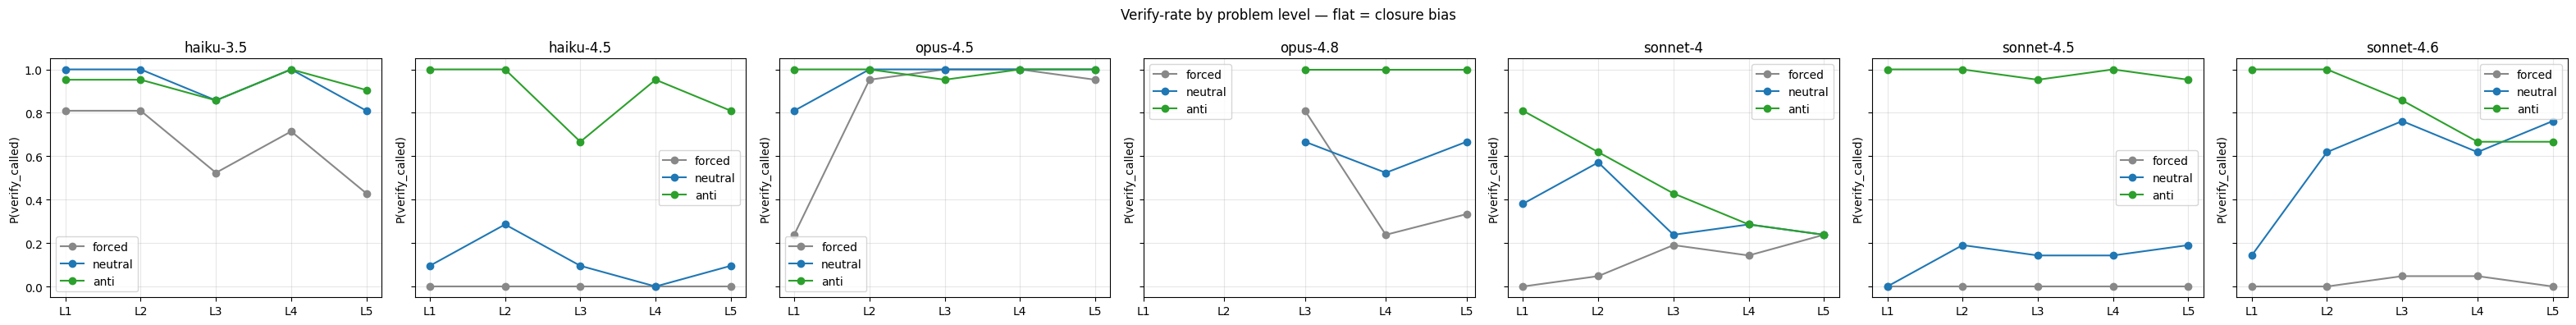

  saved results/plots_omni/verify_vs_passrate.{png,pdf}


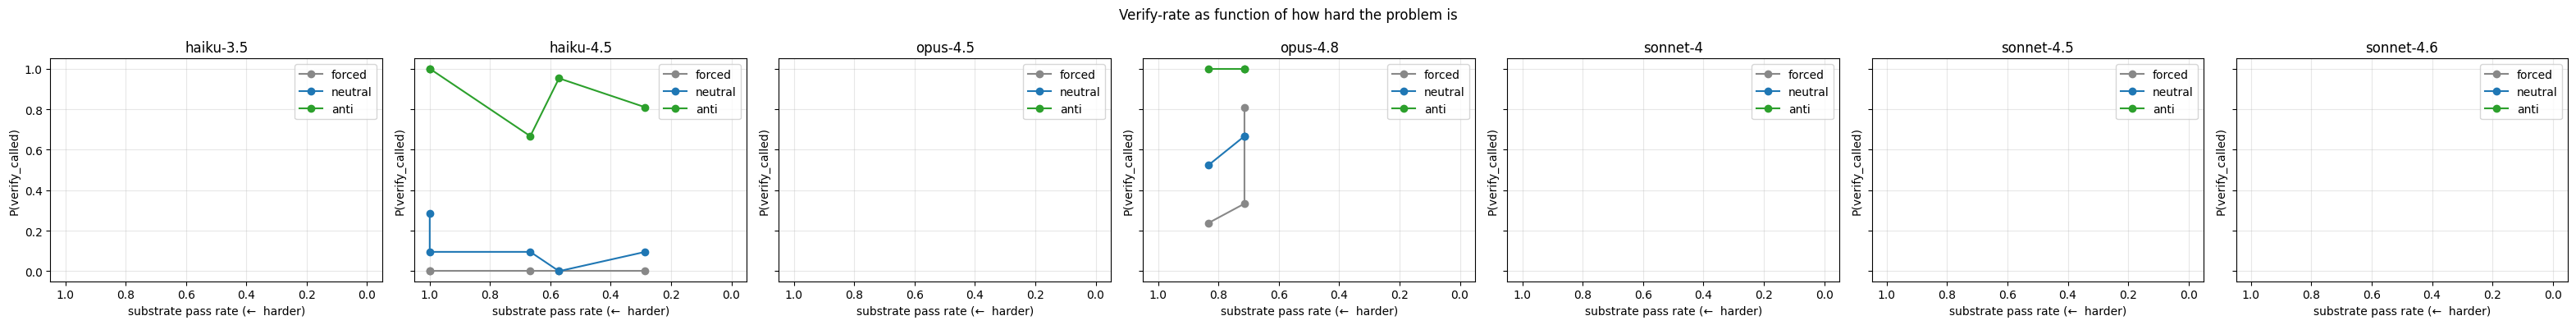

  saved results/plots_omni/accuracy_by_level.{png,pdf}


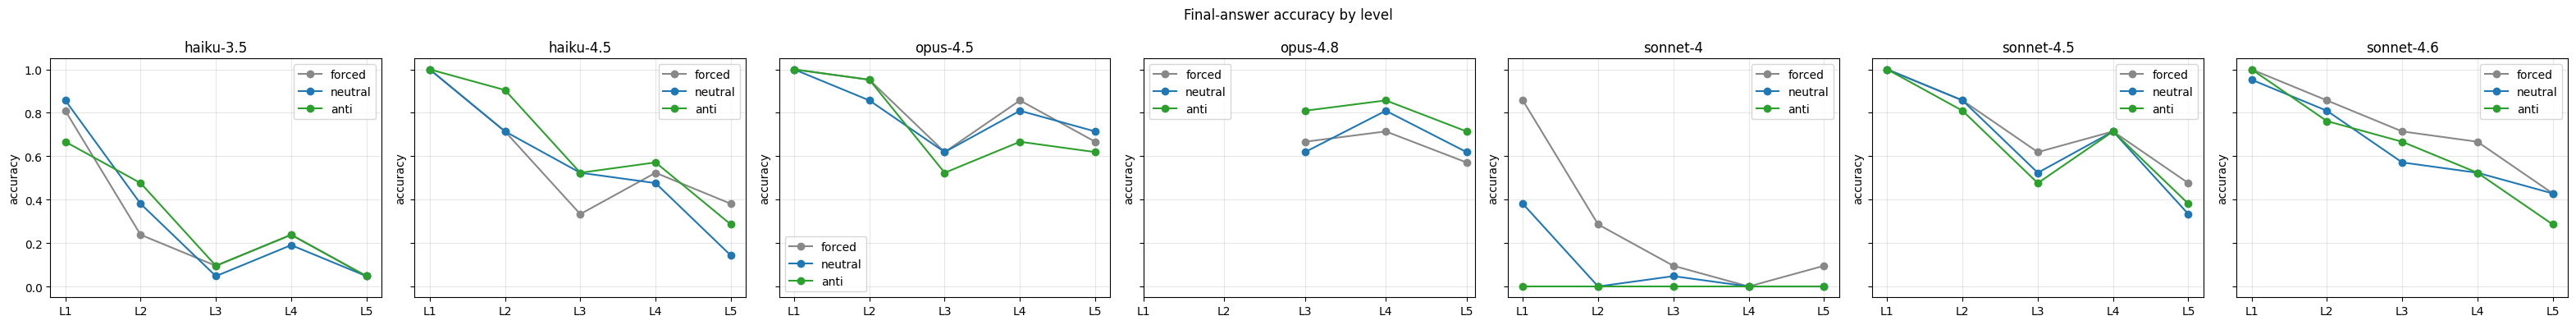

In [ ]:
plot_verify_by_level(summary)
plot_verify_vs_passrate(summary, substrate_all)
plot_accuracy_by_level(summary)

## 9. Sanity checks and caveats

Run these after the sweep to validate that the experiment's preconditions held.

- The agent really had only our tools (init message audit).
- The model called `submit` on a high fraction of trials (else `max_turns` is too tight).
- The `forced` condition had zero `verify` calls (since the tool wasn't even exposed).
- `verify` was not used as an oracle (no trial submits exactly the candidate that verify just rejected, repeatedly).

In [ ]:
df = df_all

# (a) tool isolation — every trial's init_tools should look like only mcp__probe__... .
leak = df[df["init_tools"].str.contains(r"\b(?:Bash|Read|Edit|Write|Glob|Grep|WebFetch)\b", regex=True, na=False)]
print("trials with leaked builtins in init_tools:", len(leak))

# (b) submit completion rate by condition.
sub_rate = df.groupby("condition")["submit_calls"].apply(lambda s: (s > 0).mean())
print("\nsubmit completion rate by condition:")
print(sub_rate.to_string())

# (c) forced condition exposed no verify tool — must be 0 calls.
forced_verify = df.query("condition == 'forced'")["verify_calls"].sum()
print(f"\nverify calls in forced condition (must be 0): {forced_verify}")

# (d) error count per (model, condition).
err = df[df["error"].notna()] if "error" in df.columns else df.iloc[0:0]
print(f"\nerrored trials: {len(err)}")
if len(err):
    print(err.groupby(["model_label", "condition"]).size().to_string())

# (e) total cost.
print(f"\ntotal sweep cost: ${df['cost_usd'].sum():.2f}")

trials with leaked builtins in init_tools: 0

submit completion rate by condition:
condition
anti       0.730159
forced     0.826840
neutral    0.790765

verify calls in forced condition (must be 0): 391

errored trials: 424
model_label  condition
haiku-4.5    anti          12
             forced         6
             neutral        6
opus-4.5     anti          16
             neutral        1
opus-4.8     anti           2
             forced         2
sonnet-4     anti         105
             forced       105
             neutral      105
sonnet-4.5   anti           4
sonnet-4.6   anti          31
             forced        13
             neutral       16

total sweep cost: $535.26


### Caveats and known limitations

- **Tool-design contingency.** Results are specific to this `verify`/`submit` framing. A different tool framing might reveal a smaller or larger bias. The bias is properly *operationalized*, not *defined*, by this probe.
- **Pool size.** N=3 trials × 60 problems gives noisy CIs. Scale to N=10 once headline shape is confirmed.
- **Single tool dimension.** This probe measures the *terminate-vs-recheck* dimension only. The *solve-vs-decompose* dimension needs the composed-MATH probe (notebook 03 to come).
- **Tool-use-reliability confound on old models.** If Claude 3 Haiku fails to emit valid tool calls reliably, low verify-rate could be capability rather than bias. Inspect its `init_tools`/`stop_reason` distributions before drawing conclusions for that tier.
- **Verify-as-oracle leakage.** The tool returns OK/Discrepancy. A model could in principle exploit this by submitting candidates and reading the tool's reply as ground-truth signal. Behavioral mitigation: framed as self-check, not oracle. Empirical mitigation: inspect trajectories for repeat-verify-then-submit-different-answer patterns.

### Next probes (later notebooks)

- **03 — composed-MATH depth probe** for the *solve-vs-decompose* dimension.
- **04 — disguised-decomposition probe** where the composition is hidden behind a unified word problem (pushes the bias harder).